# 03 – Visualizaciones

**Objetivo:** construir los gráficos finales del proyecto a partir de las tablas de resultados de la Etapa 4, para responder visualmente las preguntas del proyecto.

**Entradas:** las 13 tablas de `resultados/` generadas por `02_analisis.ipynb`. No se relee la base procesada.

**Salidas (7 figuras, cada una en SVG y en PNG, en `resultados/`):**

| Figura | Archivo | Pregunta |
|---|---|---|
| 1 | `fig01_ingreso_anual` (.svg y .png) | Evolución anual del ingreso de la ocupación principal |
| 2 | `fig02_ingreso_ampliado` (.svg y .png) | Qué cambia al sumar otras ocupaciones |
| 3 | `fig03_ingreso_edad` (.svg y .png) | Diferencias por grupo de edad |
| 4 | `fig04_ingreso_educacion` (.svg y .png) | Diferencias por nivel educativo |
| 5 | `fig05_ingreso_region` (.svg y .png) | Diferencias entre regiones (índice 2017 = 100) |
| 6 | `fig06_empleo_desempleo` (.svg y .png) | Empleo y desempleo |
| 7 | `fig07_resumen_etapas` (.svg y .png) | Resumen antes, durante y después |

**Formatos:** SVG (vectorial, se amplía sin perder calidad) para el notebook, el README y los documentos; PNG a 200 ppp para LinkedIn, que no acepta SVG. El PNG se agregó en la Etapa 6.

**Orden de ejecución:** después de `01_preparacion` y `02_analisis`. Ejecutar con "Reiniciar sesión y ejecutar todo". Al reiniciar la sesión, volver a ejecutar desde la sección 2.

**Unidad y referencia:** pesos de octubre de 2026; 2.º trimestre de cada año; personas de 18 años o más en aglomerados urbanos (EPH-INDEC).

**Criterios comunes de las figuras:**
- 2020 y 2021 se marcan siempre (franja gris o rayado): relevamiento no presencial.
- En las comparaciones, la media va en primer plano y la mediana la acompaña, por el agrupamiento de los ingresos declarados.
- Los niveles en pesos y las tasas empiezan en 0. Las regiones se muestran como índice 2017 = 100.
- Títulos y notas descriptivos, sin causalidad. Cada figura lleva fuente, población, ponderador y deflactor.

**Índice:** 2. Configuración · 3. Versiones · 4. Carga de las tablas · 5. Formato común · 6 a 12. Figuras 1 a 7 · 13. Control de salidas

## 2. Configuración del entorno
Imports, montaje de Google Drive y rutas del proyecto. Al reiniciar la sesión, volver a ejecutar desde acá.

In [1]:
# 2.1 Imports: todas las librerías del notebook se cargan acá
import sys                                   # para consultar la versión de Python
from pathlib import Path                     # para armar rutas de forma segura

import pandas as pd                          # lectura y manejo de tablas
import matplotlib                            # se importa entero solo para ver su versión
import matplotlib.pyplot as plt              # interfaz para crear figuras y gráficos
from matplotlib.ticker import FuncFormatter, MaxNLocator  # formato y ubicación de las marcas de los ejes

In [2]:
# 2.2 Montaje de Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# 2.3 Rutas del proyecto
RAIZ = Path('/content/drive/MyDrive/eph_ingresos')
RESULTADOS = RAIZ / 'resultados'

# Control: si alguna ruta no existe, el notebook se detiene con un mensaje claro
for ruta in [RAIZ, RESULTADOS]:
    assert ruta.exists(), f'No existe la ruta: {ruta}'
print('Rutas OK')

Rutas OK


## 3. Versiones
Versiones en uso, para compararlas con las de referencia registradas en el documento del entorno.

In [4]:
# 3. Versiones del entorno (referencia: Python 3.13.18, pandas 2.2.3, matplotlib 3.10.0)
print('Python    ', sys.version.split()[0])
print('pandas    ', pd.__version__)
print('matplotlib', matplotlib.__version__)

Python     3.13.18
pandas     2.2.3
matplotlib 3.10.0


## 4. Carga de las tablas
Lectura de las 13 tablas de resultados de la Etapa 4 en el diccionario `tablas`, con control de archivos faltantes.

In [5]:
# 4.1 Carga de las 13 tablas de resultados de la Etapa 4
NOMBRES = [
    'p21_real_anual',
    'ing_lab_real_anual',
    'p21_real_anual_edad',
    'p21_real_anual_educacion',
    'p21_real_anual_region',
    'robustez_variaciones',
    'tasas_anual',
    'resumen_etapas',
    'resumen_etapas_edad',
    'resumen_etapas_educacion',
    'resumen_etapas_region',
    'correlacion_educ_ingreso_anual',
    'sensibilidad_deflactor',
]

# Control previo: qué archivos faltan en resultados/
faltantes = [n for n in NOMBRES if not (RESULTADOS / f'{n}.csv').exists()]
assert not faltantes, f'Faltan estos archivos: {faltantes}'

# Lectura: cada tabla se guarda en un diccionario con su nombre como clave
tablas = {}
for nombre in NOMBRES:
    tablas[nombre] = pd.read_csv(RESULTADOS / f'{nombre}.csv')
    print(f'{nombre:32} {tablas[nombre].shape}')

assert len(tablas) == 13
print('\n13 tablas cargadas')

p21_real_anual                   (10, 11)
ing_lab_real_anual               (10, 11)
p21_real_anual_edad              (40, 13)
p21_real_anual_educacion         (60, 13)
p21_real_anual_region            (60, 13)
robustez_variaciones             (17, 6)
tasas_anual                      (10, 6)
resumen_etapas                   (3, 9)
resumen_etapas_edad              (12, 4)
resumen_etapas_educacion         (18, 4)
resumen_etapas_region            (18, 4)
correlacion_educ_ingreso_anual   (10, 2)
sensibilidad_deflactor           (10, 5)

13 tablas cargadas


In [6]:
# 4.2 Columnas y tipos de las dos tablas de la figura 1 (control)
for nombre in ['p21_real_anual', 'sensibilidad_deflactor']:
    print(f'\n=== {nombre} ===')
    print(tablas[nombre].dtypes)
    display(tablas[nombre].head())


=== p21_real_anual ===
ANO4         int64
n            int64
media      float64
mediana    float64
desvio     float64
p10        float64
p25        float64
p75        float64
p90        float64
riq        float64
p90_p10    float64
dtype: object


,ANO4,n,media,mediana,desvio,p10,p25,p75,p90,riq,p90_p10
0,2017,19632,1.521537e+06,1.177904e+06,1.313912e+06,353371.312082,706742.624163,1.884647e+06,2.944761e+06,1.177904e+06,8.333333
1,2018,19517,1.520488e+06,1.311551e+06,1.245543e+06,374728.835238,749457.670476,1.873644e+06,2.810466e+06,1.124187e+06,7.500000
2,2019,20985,1.319634e+06,1.141283e+06,1.163276e+06,300337.643223,600675.286445,1.741958e+06,2.402701e+06,1.141283e+06,8.000000
3,2020,10625,1.317222e+06,1.112914e+06,1.108314e+06,309142.772365,618285.544730,1.648761e+06,2.473142e+06,1.030476e+06,8.000000
4,2021,16072,1.273114e+06,1.002548e+06,1.255203e+06,282407.881223,564815.762446,1.637966e+06,2.259263e+06,1.073150e+06,8.000000



=== sensibilidad_deflactor ===
ANO4                   int64
mar-may (elegido)    float64
solo marzo           float64
solo mayo            float64
abr-jun              float64
dtype: object


,ANO4,mar-may (elegido),solo marzo,solo mayo,abr-jun
0,2017,1.521537e+06,1.555947e+06,1.494254e+06,1.495363e+06
1,2018,1.520488e+06,1.559059e+06,1.486641e+06,1.478247e+06
2,2019,1.319634e+06,1.363859e+06,1.279307e+06,1.280375e+06
3,2020,1.317222e+06,1.337239e+06,1.297504e+06,1.294379e+06
4,2021,1.273114e+06,1.322422e+06,1.229716e+06,1.229886e+06


## 5. Formato común de las figuras
Constantes y funciones que usan todas las figuras:
- `millones` y `porcentaje`: formato de los números del eje y; `pct`: formato de las variaciones porcentuales.
- `formato_base`: franja de 2020–2021, años en el eje x, grilla y bordes.
- `nota_al_pie`: fuente común más las líneas propias de cada figura.
- `paneles_por_grupo`: un panel por grupo, con la misma escala, la media y la mediana, y en el título la variación entre 2017 y 2026 y si es robusta. Con `indice=True` muestra índice 2017 = 100.
- `guardar`: guarda cada figura en SVG y en PNG con el mismo nombre.

In [7]:
# 5. Formato común de las figuras
ANIOS = list(range(2017, 2027))
FUENTE = ('Fuente: elaboración propia con datos de la EPH (INDEC), 2.º trimestre de cada año. '
          'Aglomerados urbanos.')


def millones(valor, posicion):
    """Convierte 1.234.567 en '1,2' para el eje y."""
    return f'{valor / 1e6:.1f}'.replace('.', ',')


def porcentaje(valor, posicion):
    """Convierte 57.4 en '57 %' para el eje y."""
    return f'{valor:.0f} %'


def pct(valor):
    """Convierte -18.41 en '−18,4 %'."""
    return f'{valor:+.1f} %'.replace('.', ',').replace('-', '−')


def formato_base(ax, franja_label=True):
    """Aplica a un gráfico (ax) el formato común de las series anuales."""
    etiqueta = 'Relevamiento no presencial (2020–2021)' if franja_label else None
    ax.axvspan(2019.5, 2021.5, color='grey', alpha=0.15, label=etiqueta, zorder=0)
    ax.set_xticks(ANIOS)
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)


def nota_al_pie(fig, lineas):
    """Escribe la fuente y las líneas propias de cada figura debajo del gráfico."""
    texto = '\n'.join([FUENTE] + lineas)
    fig.text(0.01, -0.01, texto, ha='left', va='top', fontsize=8, color='dimgray')


def guardar(fig, nombre):
    """Guarda la figura en resultados/ en dos formatos con el mismo nombre.

    SVG: vectorial, para el notebook, el README y los documentos.
    PNG: 200 ppp con fondo blanco, para LinkedIn (no acepta SVG).
    """
    fig.savefig(RESULTADOS / f'{nombre}.svg', bbox_inches='tight')
    fig.savefig(RESULTADOS / f'{nombre}.png', dpi=200, bbox_inches='tight', facecolor='white')


def paneles_por_grupo(tabla, col_grupo, grupos, corte, titulo, filas, columnas,
                      nombres=None, grupos_gris=(), indice=False):
    """Dibuja un panel por grupo, con la misma escala, la media y la mediana.

    tabla       tabla anual por grupo (por ejemplo, tablas['p21_real_anual_edad'])
    col_grupo   columna que identifica el grupo (por ejemplo, 'grupo_edad')
    grupos      lista de grupos, en el orden de los paneles
    corte       valor de la columna 'corte' en robustez_variaciones ('edad', 'educacion', 'region')
    titulo      título general de la figura
    filas, columnas   disposición de los paneles
    nombres     diccionario opcional {grupo: nombre para mostrar}
    grupos_gris grupos que se muestran en gris (lectura con cautela)
    indice      si es True, muestra índice 2017 = 100 en lugar de pesos
    """
    assert set(tabla[col_grupo]) == set(grupos), 'Los grupos no coinciden con la tabla'
    nombres = nombres or {}
    rob = tablas['robustez_variaciones']
    rob = rob[rob['corte'] == corte].set_index('grupo')

    ancho = min(5.5, 13 / columnas) * columnas          # 2 columnas: 11; 3 columnas: 13
    fig, axes = plt.subplots(filas, columnas, figsize=(ancho, 3.6 * filas + 0.6),
                             sharex=True, sharey=True)

    for i, (grupo, ax) in enumerate(zip(grupos, axes.flat)):
        datos = tabla[tabla[col_grupo] == grupo].sort_values('ANO4')
        media, mediana = datos['media'], datos['mediana']
        if indice:
            media = media / media.iloc[0] * 100
            mediana = mediana / mediana.iloc[0] * 100
        color = 'dimgray' if grupo in grupos_gris else 'tab:blue'

        formato_base(ax, franja_label=(i == 0))
        if indice:
            ax.axhline(100, color='black', linewidth=0.8)
        ax.plot(datos['ANO4'], media, color=color, linewidth=2.5, marker='o',
                markersize=4, label='Media')
        ax.plot(datos['ANO4'], mediana, color=color, linewidth=1.5, linestyle='--',
                label='Mediana')

        # Título del panel: nombre, variación 2017–2026 y robustez
        fila = rob.loc[grupo]
        texto = (f"{nombres.get(grupo, grupo)}\n"
                 f"media {pct(fila['var_media_%'])}, mediana {pct(fila['var_mediana_%'])}")
        if not fila['robusta']:
            texto += ' (no robusta)'
        ax.set_title(texto, loc='left', fontsize=10,
                     color='dimgray' if grupo in grupos_gris else 'black')
        ax.tick_params(axis='x', labelrotation=45)

    # Eje y compartido
    if indice:
        for ax in axes[:, 0]:
            ax.set_ylabel('Índice 2017 = 100')
    else:
        axes[0, 0].yaxis.set_major_formatter(FuncFormatter(millones))
        axes[0, 0].yaxis.set_major_locator(MaxNLocator(steps=[1, 2, 5, 10]))
        axes[0, 0].set_ylim(bottom=0)
        for ax in axes[:, 0]:
            ax.set_ylabel('Millones de pesos\nde octubre de 2026')

    alto = fig.get_figheight()
    fig.suptitle(titulo, x=0.01, y=1 - 0.05 / alto, ha='left', fontsize=14, fontweight='bold')
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper left',
               bbox_to_anchor=(0.01, 1 - 0.38 / alto), ncol=3, frameon=False)
    fig.tight_layout(rect=[0, 0, 1, 1 - 0.5 / alto])
    return fig, axes

## 6. Figura 1: evolución anual del ingreso
Media y mediana del ingreso real de la ocupación principal. La banda muestra la sensibilidad de la media al mes de referencia del IPC (limitación 11).

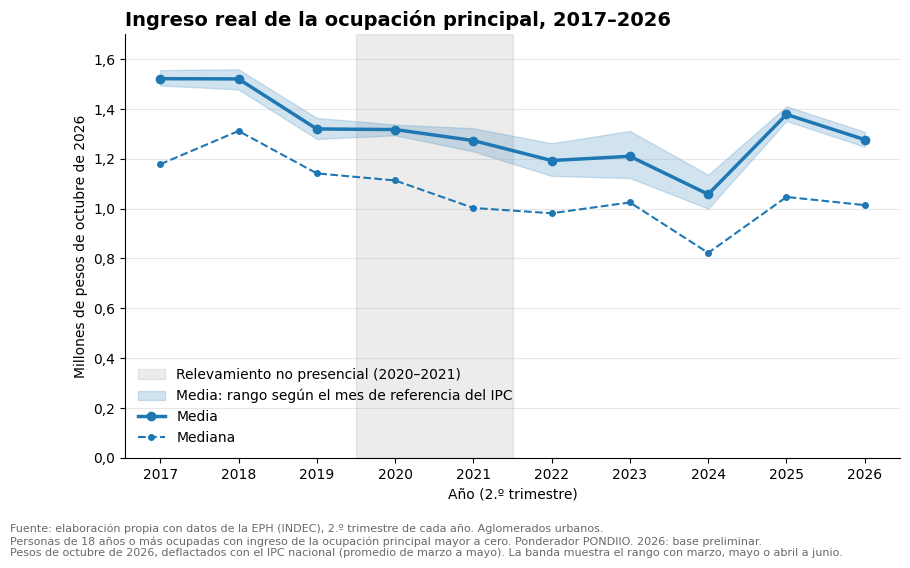

In [8]:
# 6. Figura 1: evolución anual del ingreso de la ocupación principal
anual = tablas['p21_real_anual']
sens = tablas['sensibilidad_deflactor']
anios = anual['ANO4']

# Control: las dos tablas tienen los mismos años en el mismo orden
assert (sens['ANO4'] == anios).all()

# Banda del deflactor: mínimo y máximo de los 4 escenarios, año por año
escenarios = sens.drop(columns='ANO4')
banda_min = escenarios.min(axis=1)
banda_max = escenarios.max(axis=1)

fig, ax = plt.subplots(figsize=(10, 5.5))
formato_base(ax)

# Banda de sensibilidad del deflactor (acompaña a la media)
ax.fill_between(anios, banda_min, banda_max, color='tab:blue', alpha=0.2,
                label='Media: rango según el mes de referencia del IPC')

# Media (indicador principal) y mediana (acompaña)
ax.plot(anios, anual['media'], color='tab:blue', linewidth=2.5, marker='o',
        label='Media')
ax.plot(anios, anual['mediana'], color='tab:blue', linewidth=1.5, linestyle='--',
        marker='o', markersize=4, label='Mediana')

ax.yaxis.set_major_formatter(FuncFormatter(millones))
ax.set_ylim(0, 1.7e6)
ax.set_title('Ingreso real de la ocupación principal, 2017–2026',
             loc='left', fontsize=14, fontweight='bold')
ax.set_xlabel('Año (2.º trimestre)')
ax.set_ylabel('Millones de pesos de octubre de 2026')
ax.legend(loc='lower left', frameon=False)

nota_al_pie(fig, [
    'Personas de 18 años o más ocupadas con ingreso de la ocupación principal mayor a cero. '
    'Ponderador PONDIIO. 2026: base preliminar.',
    'Pesos de octubre de 2026, deflactados con el IPC nacional (promedio de marzo a mayo). '
    'La banda muestra el rango con marzo, mayo o abril a junio.',
])

guardar(fig, 'fig01_ingreso_anual')
plt.show()

**Lectura (descriptiva).** La media cae de 1,52 millones en 2017 a un mínimo de 1,06 millones en 2024, repunta en 2025 y baja otra vez en 2026 (1,28 millones, un 16,1 % menos que en 2017). La mediana sigue el mismo recorrido, siempre por debajo de la media por la cola de ingresos altos. El mínimo de 2024 se sostiene en los cuatro escenarios del deflactor; la banda se ensancha en 2022–2024, los años de inflación mensual alta, y el repunte de 2025 se informa como rango (entre +24 % y +35 % con la media). En 2020–2021 se combinan el efecto de la pandemia y el del relevamiento no presencial, que no se pueden separar.

## 7. Figura 2: ingreso ampliado frente al de la ocupación principal
Responde la pregunta complementaria 5: qué cambia al sumar los ingresos de otras ocupaciones.

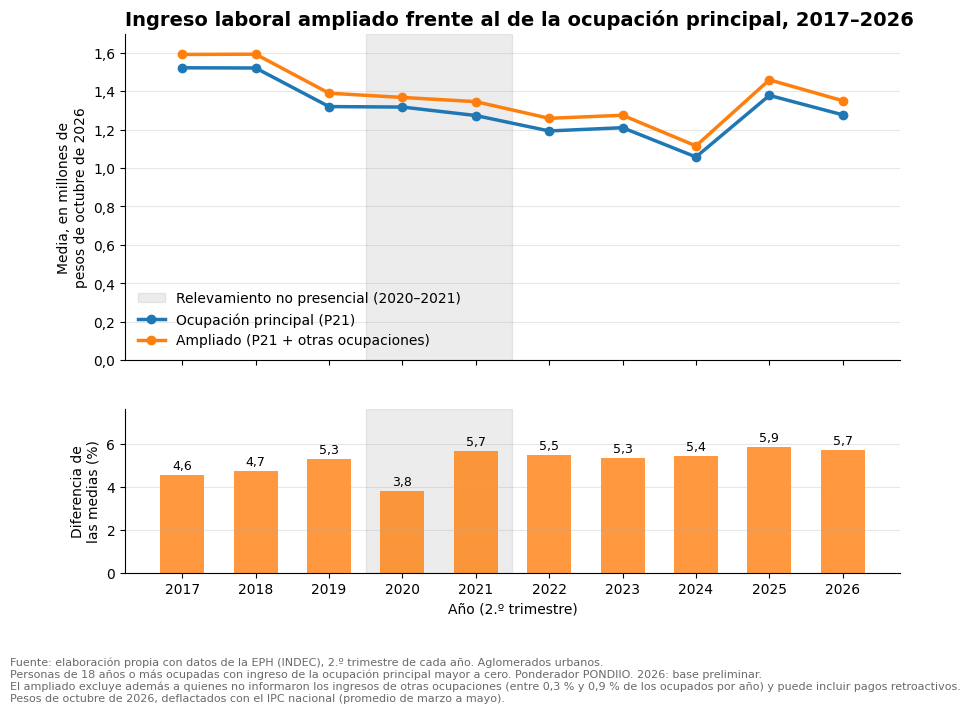

In [9]:
# 7. Figura 2: ingreso laboral ampliado frente al de la ocupación principal
central = tablas['p21_real_anual']
ampliado = tablas['ing_lab_real_anual']
assert (central['ANO4'] == ampliado['ANO4']).all()

anios = central['ANO4']
diferencia = (ampliado['media'] / central['media'] - 1) * 100   # en %

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

# Panel superior: las dos medias en millones
formato_base(ax1)
ax1.plot(anios, central['media'], color='tab:blue', linewidth=2.5, marker='o',
         label='Ocupación principal (P21)')
ax1.plot(anios, ampliado['media'], color='tab:orange', linewidth=2.5, marker='o',
         label='Ampliado (P21 + otras ocupaciones)')
ax1.yaxis.set_major_formatter(FuncFormatter(millones))
ax1.set_ylim(0, 1.7e6)
ax1.set_ylabel('Media, en millones de\npesos de octubre de 2026')
ax1.set_title('Ingreso laboral ampliado frente al de la ocupación principal, 2017–2026',
              loc='left', fontsize=14, fontweight='bold')
ax1.legend(loc='lower left', frameon=False)

# Panel inferior: cuánto supera el ampliado al central, en %
formato_base(ax2, franja_label=False)
barras = ax2.bar(anios, diferencia, color='tab:orange', alpha=0.8, width=0.6)
ax2.bar_label(barras, labels=[f'{v:.1f}'.replace('.', ',') for v in diferencia],
              padding=2, fontsize=9)
ax2.set_ylim(0, diferencia.max() * 1.3)
ax2.set_ylabel('Diferencia de\nlas medias (%)')
ax2.set_xlabel('Año (2.º trimestre)')

nota_al_pie(fig, [
    'Personas de 18 años o más ocupadas con ingreso de la ocupación principal mayor a cero. '
    'Ponderador PONDIIO. 2026: base preliminar.',
    'El ampliado excluye además a quienes no informaron los ingresos de otras ocupaciones '
    '(entre 0,3 % y 0,9 % de los ocupados por año) y puede incluir pagos retroactivos.',
    'Pesos de octubre de 2026, deflactados con el IPC nacional (promedio de marzo a mayo).',
])

guardar(fig, 'fig02_ingreso_ampliado')
plt.show()

**Lectura (descriptiva).** El ingreso ampliado supera al de la ocupación principal todos los años, entre un 3,8 % (2020) y un 5,9 % (2025), y las dos series se mueven juntas: sumar otras ocupaciones no cambia la evolución. El mínimo de 2020 cae en el período no presencial; puede reflejar una menor declaración de otras ocupaciones (limitación 3) o un cambio real, y no se pueden separar. La diferencia incluye un pequeño efecto de población, porque el ampliado excluye entre el 0,3 % y el 0,9 % de los casos, y puede incluir pagos retroactivos (limitación 10).

## 8. Figura 3: ingreso por grupo de edad
Un panel por grupo, con la misma escala. Media en primer plano y mediana como acompañamiento. En el título de cada panel van la variación entre 2017 y 2026 y si es robusta.

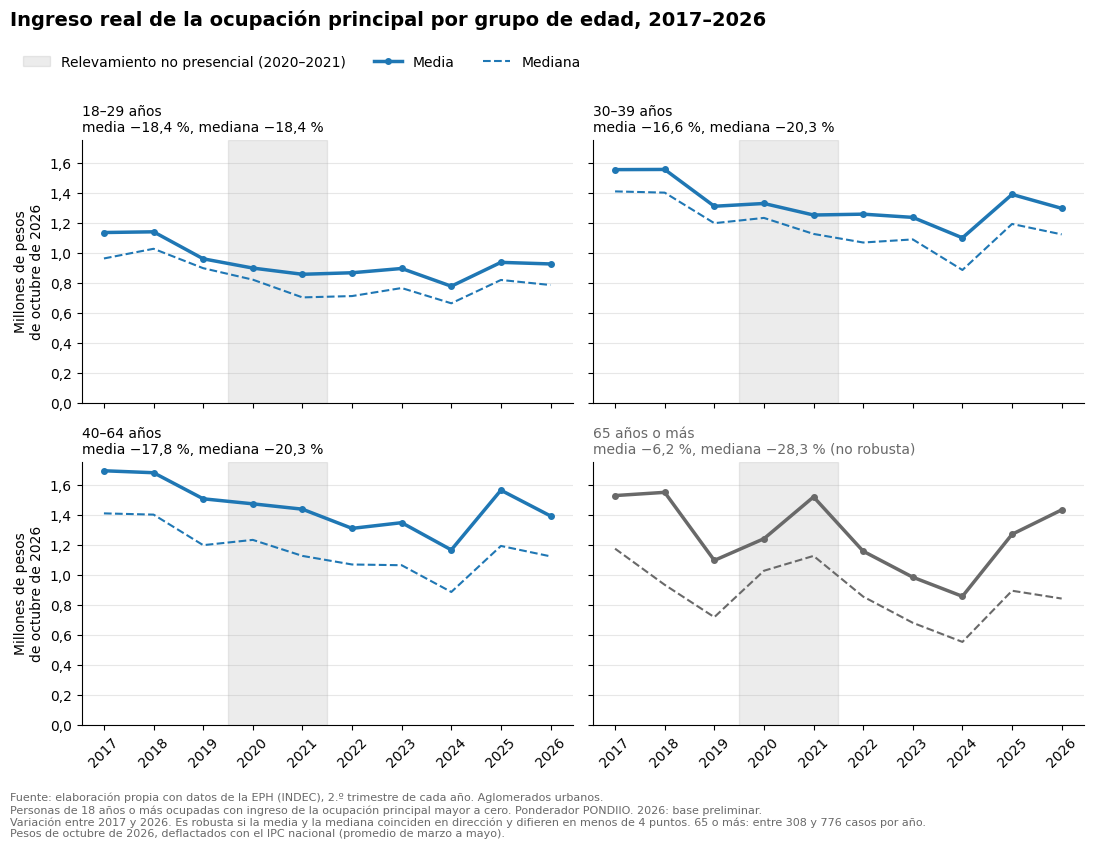

In [10]:
# 8. Figura 3: ingreso real por grupo de edad (media y mediana)
fig, axes = paneles_por_grupo(
    tablas['p21_real_anual_edad'], 'grupo_edad',
    grupos=['18-29', '30-39', '40-64', '65 o más'], corte='edad',
    titulo='Ingreso real de la ocupación principal por grupo de edad, 2017–2026',
    filas=2, columnas=2,
    nombres={'18-29': '18–29 años', '30-39': '30–39 años',
             '40-64': '40–64 años', '65 o más': '65 años o más'},
    grupos_gris=['65 o más'])
nota_al_pie(fig, [
    'Personas de 18 años o más ocupadas con ingreso de la ocupación principal mayor a cero. '
    'Ponderador PONDIIO. 2026: base preliminar.',
    'Variación entre 2017 y 2026. Es robusta si la media y la mediana coinciden en dirección '
    'y difieren en menos de 4 puntos. 65 o más: entre 308 y 776 casos por año.',
    'Pesos de octubre de 2026, deflactados con el IPC nacional (promedio de marzo a mayo).',
])
guardar(fig, 'fig03_ingreso_edad')
plt.show()

**Lectura (descriptiva).** Los grupos de 18 a 64 años caen entre un 16,6 % y un 18,4 % con la media, y las variaciones son robustas. El grupo de 18 a 29 años es siempre el de menor ingreso. Las medianas de 30–39 y 40–64 son idénticas casi todos los años por el agrupamiento de los ingresos declarados (limitación 12); la media sí los separa. En 65 años o más, la media oscila mucho y no coincide con la mediana (−6,2 % y −28,3 %): con entre 308 y 776 casos por año, no permite afirmar una tendencia.

## 9. Figura 4: ingreso por nivel educativo
Un panel por nivel, de primario incompleto a superior completo, con la misma escala.

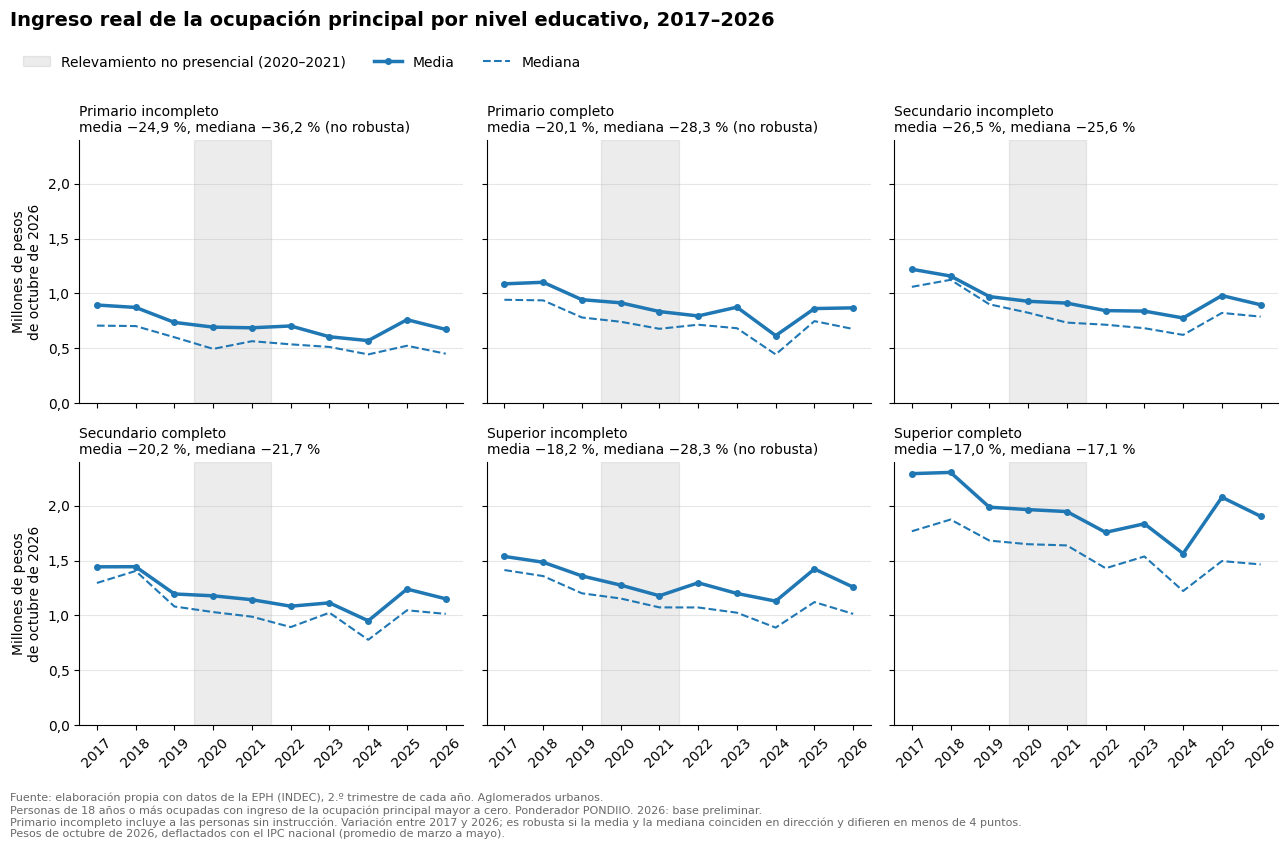

In [11]:
# 9. Figura 4: ingreso real por nivel educativo (media y mediana)
fig, axes = paneles_por_grupo(
    tablas['p21_real_anual_educacion'], 'nivel_educativo',
    grupos=['Primario incompleto', 'Primario completo', 'Secundario incompleto',
            'Secundario completo', 'Superior incompleto', 'Superior completo'],
    corte='educacion',
    titulo='Ingreso real de la ocupación principal por nivel educativo, 2017–2026',
    filas=2, columnas=3)
nota_al_pie(fig, [
    'Personas de 18 años o más ocupadas con ingreso de la ocupación principal mayor a cero. '
    'Ponderador PONDIIO. 2026: base preliminar.',
    'Primario incompleto incluye a las personas sin instrucción. Variación entre 2017 y 2026; '
    'es robusta si la media y la mediana coinciden en dirección y difieren en menos de 4 puntos.',
    'Pesos de octubre de 2026, deflactados con el IPC nacional (promedio de marzo a mayo).',
])
guardar(fig, 'fig04_ingreso_educacion')
plt.show()

**Lectura (descriptiva).** El gradiente educativo se mantiene todos los años: cada nivel está por encima del anterior, con una excepción menor en 2023 (secundario incompleto apenas debajo de primario completo). Superior completo es el nivel que menos cae (−17,0 % con la media y −17,1 % con la mediana). Entre las variaciones robustas, secundario incompleto es el que más cae (−26,5 % y −25,6 %). Primario incompleto, primario completo y superior incompleto no son robustas: la mediana cae bastante más que la media. Los cambios en la composición de cada nivel limitan la interpretación de su evolución.

## 10. Figura 5: ingreso por región (índice 2017 = 100)
Un panel por región, con índice 2017 = 100 para comparar evoluciones y no niveles: el IPC nacional no refleja las diferencias de precios entre regiones (limitación 14).

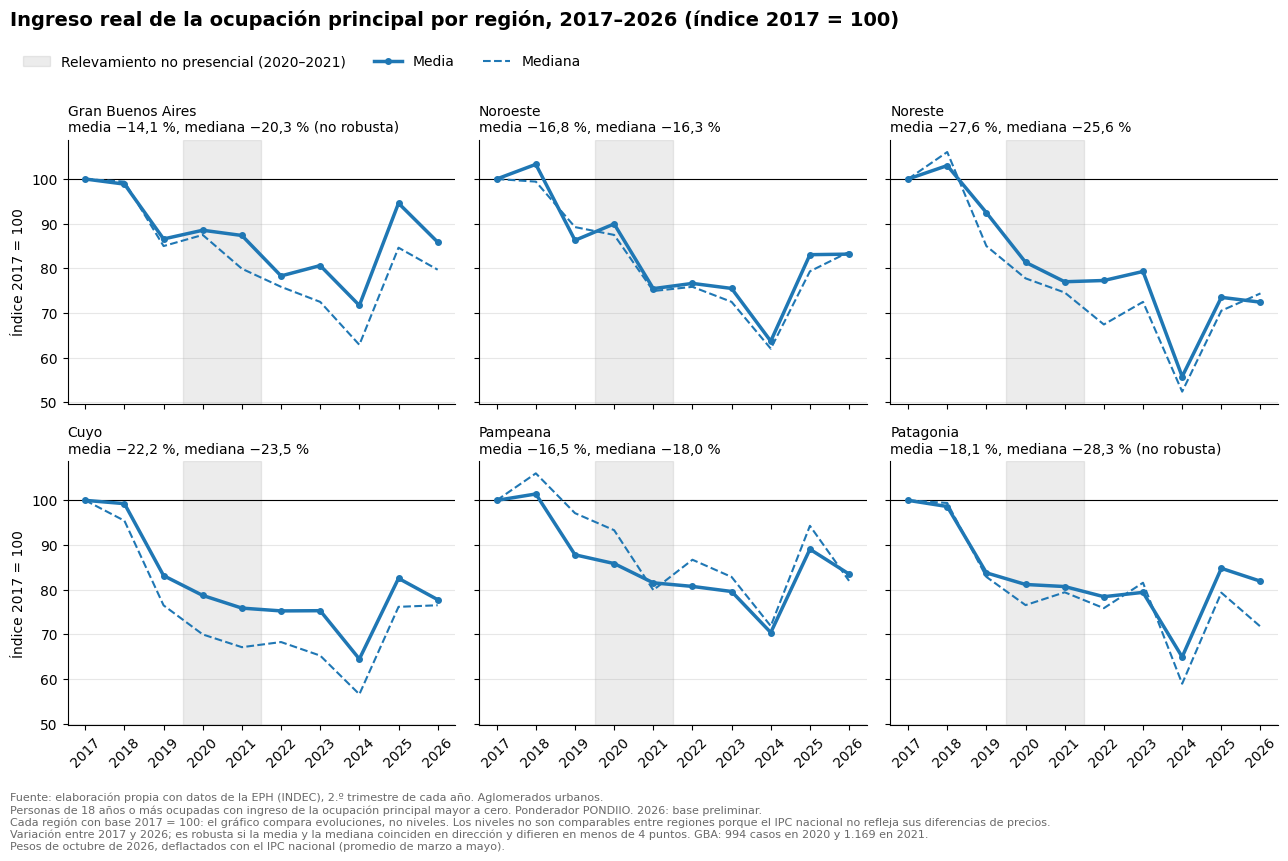

In [12]:
# 10. Figura 5: ingreso real por región (índice 2017 = 100)
fig, axes = paneles_por_grupo(
    tablas['p21_real_anual_region'], 'region',
    grupos=['Gran Buenos Aires', 'Noroeste', 'Noreste', 'Cuyo', 'Pampeana', 'Patagonia'],
    corte='region',
    titulo='Ingreso real de la ocupación principal por región, 2017–2026 (índice 2017 = 100)',
    filas=2, columnas=3, indice=True)
nota_al_pie(fig, [
    'Personas de 18 años o más ocupadas con ingreso de la ocupación principal mayor a cero. '
    'Ponderador PONDIIO. 2026: base preliminar.',
    'Cada región con base 2017 = 100: el gráfico compara evoluciones, no niveles. Los niveles no son '
    'comparables entre regiones porque el IPC nacional no refleja sus diferencias de precios.',
    'Variación entre 2017 y 2026; es robusta si la media y la mediana coinciden en dirección y difieren '
    'en menos de 4 puntos. GBA: 994 casos en 2020 y 1.169 en 2021.',
    'Pesos de octubre de 2026, deflactados con el IPC nacional (promedio de marzo a mayo).',
])
guardar(fig, 'fig05_ingreso_region')
plt.show()

**Lectura (descriptiva).** En 2026, todas las regiones están por debajo de 2017, y 2024 es el mínimo en las seis. Noreste es la que más cae (−27,6 % con la media y −25,6 % con la mediana). Noroeste, Cuyo y Pampeana tienen variaciones robustas, de entre −16 % y −24 %. Gran Buenos Aires (−14,1 % y −20,3 %) y Patagonia (−18,1 % y −28,3 %) no son robustas. Gran Buenos Aires tiene alrededor de un tercio de los casos habituales en 2020–2021, y esos son sus puntos menos precisos (limitación 2).

## 11. Figura 6: empleo y desempleo
Contexto del mercado de trabajo: tasa de empleo y tasa de desempleo de la población de 18 años o más, con PONDERA.

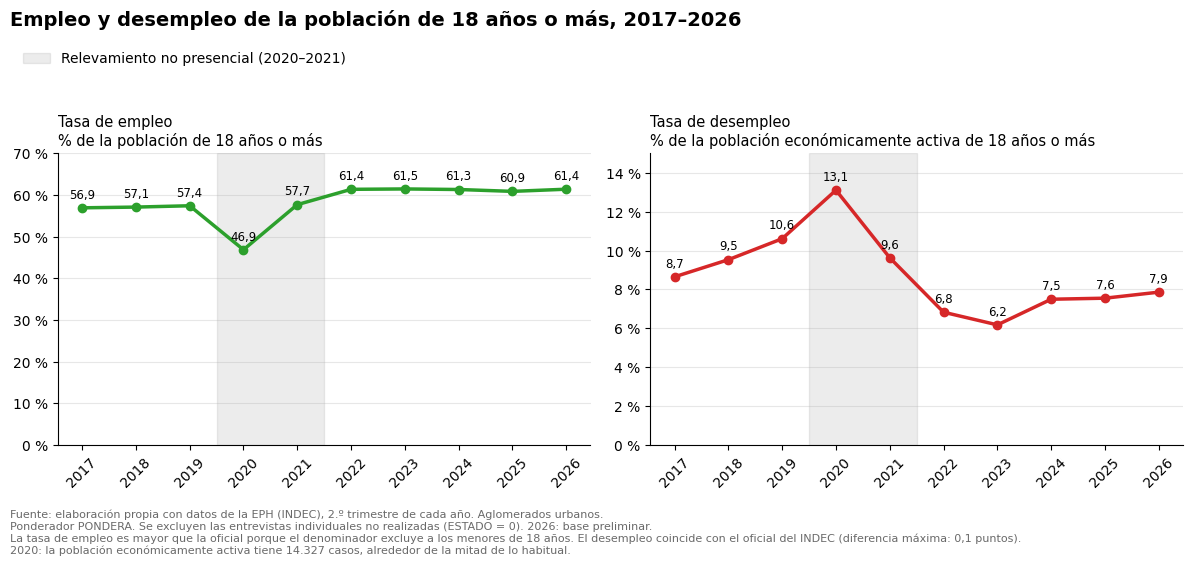

In [13]:
# 11. Figura 6: tasas de empleo y de desempleo
tasas = tablas['tasas_anual']
anios = tasas['ANO4']



fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
paneles = [
    (ax1, 'tasa_empleo', 'tab:green', 70,
     'Tasa de empleo\n% de la población de 18 años o más'),
    (ax2, 'tasa_desempleo', 'tab:red', 15,
     'Tasa de desempleo\n% de la población económicamente activa de 18 años o más'),
]

for i, (ax, columna, color, tope, titulo) in enumerate(paneles):
    formato_base(ax, franja_label=(i == 0))
    ax.plot(anios, tasas[columna], color=color, linewidth=2.5, marker='o')
    for x, y in zip(anios, tasas[columna]):
        ax.annotate(f'{y:.1f}'.replace('.', ','), (x, y), textcoords='offset points',
                    xytext=(0, 7), ha='center', fontsize=8.5)
    ax.set_ylim(0, tope)
    ax.yaxis.set_major_formatter(FuncFormatter(porcentaje))
    ax.set_title(titulo, loc='left', fontsize=10.5)
    ax.tick_params(axis='x', labelrotation=45)

fig.suptitle('Empleo y desempleo de la población de 18 años o más, 2017–2026',
             x=0.01, y=0.99, ha='left', fontsize=14, fontweight='bold')
fig.legend(*ax1.get_legend_handles_labels(), loc='upper left',
           bbox_to_anchor=(0.01, 0.93), frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.88])

nota_al_pie(fig, [
    'Ponderador PONDERA. Se excluyen las entrevistas individuales no realizadas (ESTADO = 0). '
    '2026: base preliminar.',
    'La tasa de empleo es mayor que la oficial porque el denominador excluye a los menores de 18 años. '
    'El desempleo coincide con el oficial del INDEC (diferencia máxima: 0,1 puntos).',
    '2020: la población económicamente activa tiene 14.327 casos, alrededor de la mitad de lo habitual.',
])

guardar(fig, 'fig06_empleo_desempleo')
plt.show()

**Lectura (descriptiva).** En 2020 el empleo cae del 57,4 % al 46,9 % y el desempleo sube del 10,6 % al 13,1 %: la caída del empleo es mucho mayor que la suba del desempleo porque muchas personas pasaron a la inactividad. Desde 2022 el empleo se mantiene en alrededor del 61 %, por encima de 2017–2019. El desempleo baja a su mínimo en 2023 (6,2 %) y después sube hasta el 7,9 % en 2026.

## 12. Figura 7: resumen de las tres etapas
Ingreso real, empleo y desempleo promediados por etapa: antes (2017–2019), durante (2020–2021) y después (2022–2026).

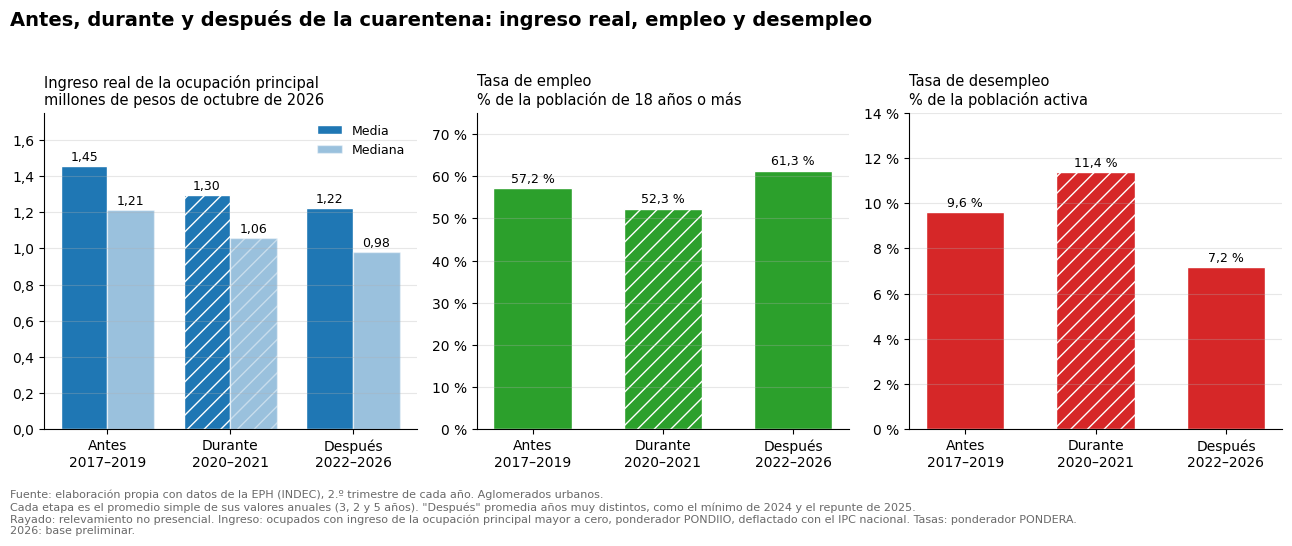

In [14]:
# 12. Figura 7: resumen de las tres etapas
etapas = tablas['resumen_etapas']
assert list(etapas['etapa']) == ['antes', 'durante', 'después']

ETIQUETAS = ['Antes\n2017–2019', 'Durante\n2020–2021', 'Después\n2022–2026']
x = etapas.index                           # posiciones 0, 1, 2
RAYADO = ['', '//', '']                    # rayado en "durante": relevamiento no presencial


def rotular(ax, barras, valores, formato):
    """Escribe el valor arriba de cada barra con el formato indicado."""
    ax.bar_label(barras, labels=[formato(v) for v in valores], padding=2, fontsize=9)


fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4.8))

# Panel 1: ingreso real, media y mediana (barras agrupadas)
ancho = 0.38
b1 = ax1.bar(x - ancho / 2, etapas['p21_media'], ancho, color='tab:blue',
             hatch=RAYADO, edgecolor='white', label='Media')
b2 = ax1.bar(x + ancho / 2, etapas['p21_mediana'], ancho, color='tab:blue', alpha=0.45,
             hatch=RAYADO, edgecolor='white', label='Mediana')
for barras, col in [(b1, 'p21_media'), (b2, 'p21_mediana')]:
    rotular(ax1, barras, etapas[col], lambda v: f'{v / 1e6:.2f}'.replace('.', ','))
ax1.yaxis.set_major_formatter(FuncFormatter(millones))
ax1.set_ylim(0, 1.75e6)
ax1.set_title('Ingreso real de la ocupación principal\nmillones de pesos de octubre de 2026',
              loc='left', fontsize=10.5)
ax1.legend(loc='upper right', frameon=False, fontsize=9)

# Paneles 2 y 3: tasas
for ax, col, color, tope, titulo in [
        (ax2, 'tasa_empleo', 'tab:green', 75, 'Tasa de empleo\n% de la población de 18 años o más'),
        (ax3, 'tasa_desempleo', 'tab:red', 14, 'Tasa de desempleo\n% de la población activa')]:
    barras = ax.bar(x, etapas[col], 0.6, color=color, hatch=RAYADO, edgecolor='white')
    rotular(ax, barras, etapas[col], lambda v: f'{v:.1f} %'.replace('.', ','))
    ax.set_ylim(0, tope)
    ax.yaxis.set_major_formatter(FuncFormatter(porcentaje))
    ax.set_title(titulo, loc='left', fontsize=10.5)

for ax in (ax1, ax2, ax3):
    ax.set_xticks(x, ETIQUETAS)
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Antes, durante y después de la cuarentena: ingreso real, empleo y desempleo',
             x=0.01, y=0.99, ha='left', fontsize=14, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96])

nota_al_pie(fig, [
    'Cada etapa es el promedio simple de sus valores anuales (3, 2 y 5 años). "Después" promedia años muy '
    'distintos, como el mínimo de 2024 y el repunte de 2025.',
    'Rayado: relevamiento no presencial. Ingreso: ocupados con ingreso de la ocupación principal mayor a cero, '
    'ponderador PONDIIO, deflactado con el IPC nacional. Tasas: ponderador PONDERA.',
    '2026: base preliminar.',
])

guardar(fig, 'fig07_resumen_etapas')
plt.show()

**Lectura (descriptiva).** El ingreso real medio pasa de 1,45 millones antes a 1,30 durante y 1,22 después: sigue bajando después de "durante". El empleo pasa del 57,2 % al 52,3 % y al 61,3 %, y el desempleo del 9,6 % al 11,4 % y al 7,2 %. En "después" hay más empleo y menos desempleo que en "antes", con un ingreso real alrededor de un 16 % menor. "Después" promedia cinco años muy distintos, así que cualquier afirmación sobre esa etapa debe contrastarse con las figuras 1 y 6. Es una descripción: no implica que la cuarentena haya causado estos cambios.

## 13. Control de salidas
Comprueba que las 7 figuras estén guardadas en `resultados/` en los dos formatos, SVG y PNG.

In [15]:
# 13. Control de salidas
FIGURAS = [
    'fig01_ingreso_anual',
    'fig02_ingreso_ampliado',
    'fig03_ingreso_edad',
    'fig04_ingreso_educacion',
    'fig05_ingreso_region',
    'fig06_empleo_desempleo',
    'fig07_resumen_etapas',
]
FORMATOS = ['svg', 'png']

faltantes = [f'{f}.{ext}' for f in FIGURAS for ext in FORMATOS
             if not (RESULTADOS / f'{f}.{ext}').exists()]
assert not faltantes, f'Faltan estas figuras: {faltantes}'

print(f"{'Figura':26} {'SVG (KB)':>9} {'PNG (KB)':>9}")
for f in FIGURAS:
    tamanios = [(RESULTADOS / f'{f}.{ext}').stat().st_size / 1024 for ext in FORMATOS]
    print(f'{f:26} {tamanios[0]:9.0f} {tamanios[1]:9.0f}')
print('\n7 figuras guardadas en resultados/, en SVG y PNG')

Figura                      SVG (KB)  PNG (KB)
fig01_ingreso_anual               95       213
fig02_ingreso_ampliado           119       228
fig03_ingreso_edad               146       341
fig04_ingreso_educacion          169       351
fig05_ingreso_region             180       416
fig06_empleo_desempleo           127       227
fig07_resumen_etapas             132       237

7 figuras guardadas en resultados/, en SVG y PNG
